# Validate against buoys

Compare **metamodel** and **dynamic SnapWave** against buoy observations
(`inputs/JennBuoys/processed/`) for a user-specified time window.

Prerequisites:

1. `spectral_metamodel.nc` includes the buoy sites you want to validate.
2. Dynamic SnapWave output (`Dynamic_Cases_*.nc`) covers the same period.
3. Buoy pickle files exist for those instruments.

Set `time` and `buoys` below, then run `validate_buoys()`.

In [1]:
from utils import metamodel as mm
from utils import validation as val
from utils.config import get_buoy_coordinates, validation_period_var

print(f"metamodel : {mm.spectral_output_path()}")
print(f"dynamic   : {val.dynamic_output_path()}")
print(f"period    : {validation_period_var()}")

metamodel : /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/outputs/spectral_metamodel.nc
dynamic   : /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/SnapWave_CASES_Dynamic/Dynamic_Cases_198601.nc
period    : tp


In [2]:
# Buoy ids to validate (None = all buoys with role "validation" in GeoJSON).
buoys = [
    "41007",
]

# Pick a period with buoy + model overlap (buoy records are ~2003–2023).
time = "1986-01"

available = get_buoy_coordinates(role="validation")
print(f"{len(available)} validation buoys in config")

21 validation buoys in config


In [3]:
result = val.validate_buoys(time=time, buoys=buoys)

print(f"{len(result.sites)} buoy site(s)")
result.metrics

2026-06-17 16:12:13,598 - NorthCarolina.validation - INFO - Loading metamodel from /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/outputs/spectral_metamodel.nc


2026-06-17 16:12:13,769 - NorthCarolina.validation - INFO - Loading dynamic reference from /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/SnapWave_CASES_Dynamic/Dynamic_Cases_198601.nc
2026-06-17 16:12:13,790 - NorthCarolina.validation - INFO - Aligned 1 buoy site(s), 318 time step(s) for models ['metamodel', 'dynamic']
2026-06-17 16:12:13,798 - NorthCarolina.validation - INFO - Computed metrics (site grouping): 3 row(s)
2026-06-17 16:12:13,808 - NorthCarolina.validation - INFO - Computed metrics (site grouping): 3 row(s)
2026-06-17 16:12:13,810 - NorthCarolina.validation - INFO - [buoy] metamodel Hs (buoy_41007): n=318  RMSE=0.593  BIAS=-0.395  R²=0.369
2026-06-17 16:12:13,811 - NorthCarolina.validation - INFO - [buoy] metamodel Tp (buoy_41007): n=318  RMSE=1.565  BIAS=-0.444  R²=-0.161
2026-06-17 16:12:13,811 - NorthCarolina.validation - INFO - [buoy] metamodel Dm (buoy_41007): n=0  RMSE=nan  BIAS=nan  R²=n/a
2026-06-17 16:12:13,812 - NorthCarolina.validation - INFO - [buoy] dyna

1 buoy site(s)


,model,group,variable,label,n,bias,rmse,si,r2,site_label,site_depth
0,metamodel,buoy_41007,hs,Hs,318,-0.395250,0.592988,0.219618,0.368639,waves,nan
1,metamodel,buoy_41007,tp,Tp,318,-0.443593,1.564740,0.195024,-0.161441,waves,nan
2,metamodel,buoy_41007,dm,Dm,0,NaN,NaN,NaN,NaN,waves,nan
3,dynamic,buoy_41007,hs,Hs,318,-0.525085,0.694429,0.242781,-0.009504,waves,nan
4,dynamic,buoy_41007,tp,Tp,318,-0.282651,1.514076,0.190829,-0.898941,waves,nan
5,dynamic,buoy_41007,dm,Dm,0,NaN,NaN,NaN,NaN,waves,nan


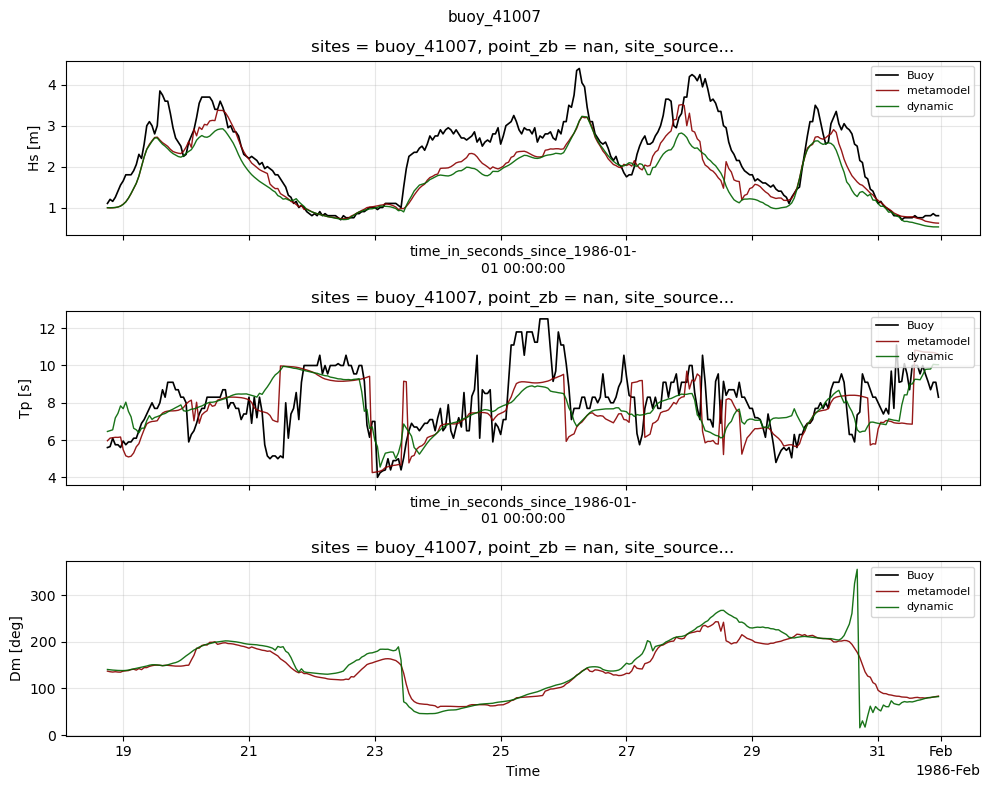

In [6]:
site = result.sites[0]
val.plot_buoy_timeseries(result, site=site);